# NOC Satelital — análisis del prototipo

Gráficos para el documento del TFI y la demo. El notebook **solo consume la API**: todo el cálculo (órbitas, Doppler, enlace, validación) ocurre en el backend.

**Cómo correrlo**

```bash
cd backend
uv sync --group notebook
uv run uvicorn main:app            # en otra terminal
uv run --group notebook jupyter nbconvert --to notebook --execute --inplace notebooks/analisis.ipynb
```

Sin conexión a SatNOGS, el backend responde desde `backend/cache/` (header `X-Source`).

In [1]:
import os
from datetime import datetime

import httpx
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BASE_URL = os.getenv('NOC_API', 'http://127.0.0.1:8000')
SAT_ID = os.getenv('NOC_SAT_ID', 'ZDPY-4221-9426-0630-5344')  # LUSAT
VALIDATION_SAT_ID = os.getenv('NOC_VALIDATION_SAT_ID', 'XSKZ-5603-1870-9019-3066')  # ISS: más observaciones

api = httpx.Client(base_url=BASE_URL, timeout=180)

def get(path, **params):
    response = api.get(path, params=params)
    response.raise_for_status()
    print(f"{path}: X-Source={response.headers.get('X-Source')}, X-Cache-Age={response.headers.get('X-Cache-Age')}s")
    return response.json()

def when(iso):
    return datetime.fromisoformat(iso.replace('Z', '+00:00'))

## 1. Órbita del satélite

In [2]:
orbit = get('/orbits/classify', sat_id=SAT_ID)
for key in ['name', 'orbit_type', 'period_min', 'altitude_km', 'perigee_km', 'apogee_km',
            'inclination_deg', 'footprint_radius_km', 'tle_epoch', 'tle_age_days']:
    value = orbit[key]
    print(f'{key:>22}: {value:.2f}' if isinstance(value, float) else f'{key:>22}: {value}')

/orbits/classify: X-Source=cache, X-Cache-Age=2059s
                  name: 0 OSCAR 19 (LUSAT)
            orbit_type: LEO
            period_min: 100.41
           altitude_km: 785.02
            perigee_km: 776.89
             apogee_km: 793.15
       inclination_deg: 98.88
   footprint_radius_km: 2084.29
             tle_epoch: 2026-10-21T12:45:36Z
          tle_age_days: 0.32


## 2. Agenda de pases con margen de enlace (estación de referencia)

In [3]:
agenda = get('/predictions/passes', sat_id=SAT_ID, days=2)
print(f"Estación {agenda['station']}, máscara {agenda['min_elevation_deg']}°\n")
print(f"{'AOS (UTC)':<22}{'LOS':<10}{'dur':>6}{'elev máx':>10}{'margen AOS':>12}{'margen TCA':>12}")
for p in agenda['passes']:
    link = p['link'] or {}
    fmt = lambda v: f'{v:10.1f} dB' if v is not None else '         —'
    print(f"{p['aos']:<22}{p['los'][11:19]:<10}{p['duration_s']/60:5.1f}m{p['max_elevation_deg']:9.1f}°"
          f"{fmt(link.get('margin_at_aos_db'))}{fmt(link.get('margin_at_tca_db'))}")

/predictions/passes: X-Source=cache, X-Cache-Age=2059s
Estación {'lat': -34.5627, 'lng': -58.4566, 'alt_m': 25.0}, máscara 10.0°

AOS (UTC)             LOS          dur  elev máx  margen AOS  margen TCA
2026-10-21T22:35:05Z  22:43:17    8.2m     23.3°      20.5 dB      23.8 dB
2026-10-22T00:13:41Z  00:23:05    9.4m     35.4°      20.5 dB      26.0 dB
2026-10-22T09:47:59Z  09:56:14    8.2m     24.8°      20.6 dB      24.2 dB
2026-10-22T11:26:30Z  11:35:43    9.2m     33.0°      20.7 dB      25.8 dB
2026-10-22T22:05:39Z  22:06:00    0.3m     10.0°      20.5 dB      20.5 dB
2026-10-22T23:40:15Z  23:50:40   10.4m     76.3°      20.4 dB      29.7 dB
2026-10-23T09:17:36Z  09:21:16    3.7m     11.9°      20.6 dB      21.1 dB
2026-10-23T10:52:49Z  11:03:06   10.3m     73.4°      20.7 dB      29.8 dB


## 3. Curva Doppler del próximo pase

Frecuencia a sintonizar: arranca por encima de la nominal (el satélite se acerca), la cruza en el TCA y termina por debajo (TFI §3.6).

/predictions/doppler: X-Source=cache, X-Cache-Age=2059s


corrimiento máx 7341 Hz, pendiente máx -43.8 Hz/s


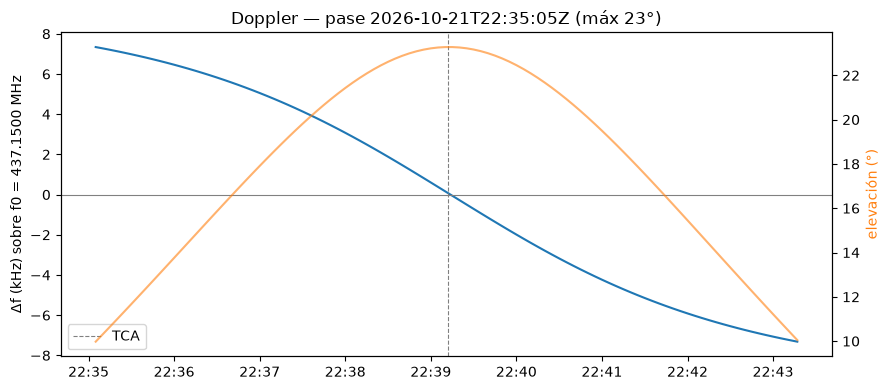

In [4]:
dop = get('/predictions/doppler', sat_id=SAT_ID, step=5)
times = [when(p['t']) for p in dop['points']]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(times, [p['shift_hz'] / 1e3 for p in dop['points']], color='tab:blue')
ax.axhline(0, color='grey', lw=0.8)
ax.axvline(when(dop['pass']['tca']), color='grey', ls='--', lw=0.8, label='TCA')
ax.set_ylabel(f"Δf (kHz) sobre f0 = {dop['f0_hz']/1e6:.4f} MHz")
ax.set_title(f"Doppler — pase {dop['pass']['aos']} (máx {dop['pass']['max_elevation_deg']:.0f}°)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
elev = ax.twinx()
elev.plot(times, [p['elevation_deg'] for p in dop['points']], color='tab:orange', alpha=0.6)
elev.set_ylabel('elevación (°)', color='tab:orange')
ax.legend(loc='lower left')
plt.tight_layout()
print(f"corrimiento máx {dop['max_shift_hz']:.0f} Hz, pendiente máx {dop['max_rate_hz_s']:.1f} Hz/s")

## 4. Margen de enlace a lo largo del pase

Margen = Eb/N0 − umbral del modo (BER 1e-5). Optimista: sin pérdidas atmosféricas, de polarización ni de apuntamiento (TFI §3.7).

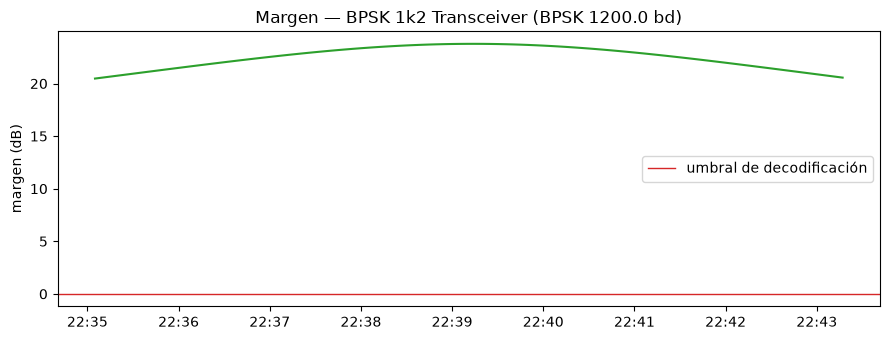

In [5]:
margins = [p['margin_db'] for p in dop['points']]
if all(m is None for m in margins):
    print('El transmisor no tiene un modo digital con umbral: no hay margen.')
else:
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(times, margins, color='tab:green')
    ax.axhline(0, color='tab:red', lw=1, label='umbral de decodificación')
    ax.set_ylabel('margen (dB)')
    tx = dop['transmitter'] or {}
    ax.set_title(f"Margen — {tx.get('description')} ({tx.get('mode')} {tx.get('baud')} bd)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.legend()
    plt.tight_layout()

## 5. Validación contra observaciones reales de SatNOGS

Cada observación se predice con el TLE embebido en ella, desde su propia estación. Ver las notas que devuelve el endpoint: qué valida y qué no.

In [6]:
report = get('/validation/satellite', sat_id=VALIDATION_SAT_ID, days=7)
print(f"{report['summary']['count']} observaciones, {len(report['skipped'])} descartadas\n")
for metric, stats in report['summary'].items():
    if isinstance(stats, dict):
        print(f"{metric:>26}: media {stats['mean']:8.2f}  |e| media {stats['mean_abs']:7.2f}  "
              f"|e| máx {stats['max_abs']:7.2f}  p95 {stats['p95_abs']:7.2f}")
print()
for note in report['notes']:
    print('•', note)

/validation/satellite: X-Source=cache, X-Cache-Age=97s
25 observaciones, 0 descartadas

             error_start_s: media  -112.72  |e| media  112.72  |e| máx  222.00  p95  217.80
               error_end_s: media   117.40  |e| media  117.40  |e| máx  276.00  p95  224.00
   error_max_elevation_deg: media    -0.02  |e| media    0.27  |e| máx    0.53  p95    0.52
    error_rise_azimuth_deg: media    -0.01  |e| media    0.21  |e| máx    0.46  p95    0.44
     error_set_azimuth_deg: media    -0.02  |e| media    0.28  |e| máx    0.52  p95    0.50

• Each observation is predicted with the TLE embedded in it, at its own station.
• Elevation and azimuths are compared inside the observation's scheduled window; SatNOGS rounds them to whole degrees.
• error_start_s/error_end_s compare against the full pass at 0°: they include the station scheduler cutting the window, not only prediction error.
• SatNOGS start/end come from its own SGP4 prediction, so agreement validates the implementation, not th

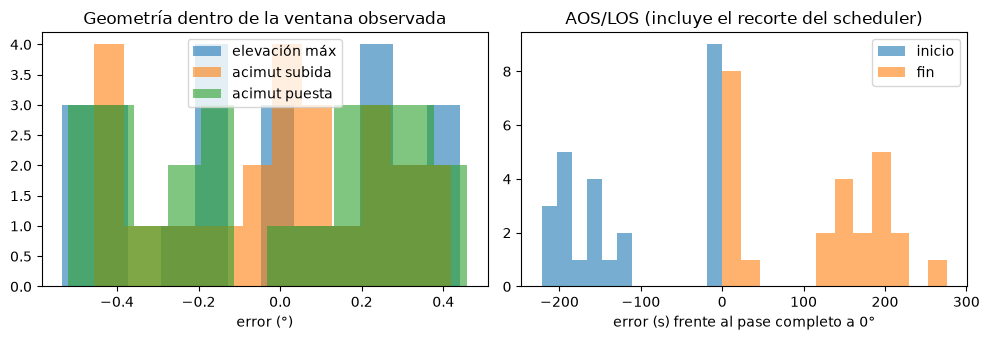

In [7]:
rows = report['observations']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for metric, label in [('error_max_elevation_deg', 'elevación máx'),
                      ('error_rise_azimuth_deg', 'acimut subida'),
                      ('error_set_azimuth_deg', 'acimut puesta')]:
    axes[0].hist([r[metric] for r in rows if r[metric] is not None], bins=12, alpha=0.6, label=label)
axes[0].set_xlabel('error (°)')
axes[0].set_title('Geometría dentro de la ventana observada')
axes[0].legend()
for metric, label in [('error_start_s', 'inicio'), ('error_end_s', 'fin')]:
    axes[1].hist([r[metric] for r in rows if r[metric] is not None], bins=12, alpha=0.6, label=label)
axes[1].set_xlabel('error (s) frente al pase completo a 0°')
axes[1].set_title('AOS/LOS (incluye el recorte del scheduler)')
axes[1].legend()
plt.tight_layout()